# 一般病院が少ない県のTOP10と、高齢者人口

- **氏名**：林崎 仁
- **依頼元**：地方自治体の医療・福祉政策を担当する部署
- **読み手**：同部署の職員・上司
- **調べたい問い**：一般病院の数が少ない都道府県TOP10はどこか。その県の65歳以上人口と総人口はどうなっているか。病院が少ない県ほど高齢者も少ないと言えるか。

※Week05の題材の続き

※グラフの県名は、文字化けを避けるため英語表記のまま。また、上から順番にプログラムを実行しないとエラーが起きるので注意

## 準備・データ読み込み

In [1]:
import csv
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# japan.csv は、このNotebookと同じフォルダに置く
with open("japan.csv", encoding="utf-8-sig", newline="") as file:
    data = list(csv.DictReader(file))

print(len(data), "prefectures")

47 prefectures


## データの確認

In [2]:
need = ["Prefecture", "都道府県", "総人口", "65歳以上人口", "一般病院数"]
missing = [c for c in need if c not in data[0]]
print("足りない列:", missing if missing else "なし")

first = data[0]
print({c: first[c] for c in need})

足りない列: なし
{'Prefecture': 'Hokkaido', '都道府県': '北海道', '総人口': '5140000', '65歳以上人口': '1686000', '一般病院数': '471'}


## 一般病院数が少ないTOP10を選ぶ

一般病院数の**少ない順**に並べ、先頭10件を取る。表やグラフに使う値を計算する。

- 65歳以上の割合（%）＝ 65歳以上人口 ÷ 総人口 × 100
- 高齢者数÷病院数 ＝ 病院1つあたりの65歳以上人口（病院の負担の目安）

In [3]:
top10 = sorted(data, key=lambda row: int(row["一般病院数"]))[:10]

rows = []
for rank, row in enumerate(top10, start=1):
    hospitals = int(row["一般病院数"])
    elderly = int(row["65歳以上人口"])
    total = int(row["総人口"])
    rows.append({
        "rank": rank,
        "ja": row["都道府県"],
        "en": row["Prefecture"],
        "hospitals": hospitals,
        "elderly": elderly,
        "total": total,
        "share": elderly / total * 100,
        "per_hospital": elderly / hospitals,
    })

for r in rows:
    print(r["rank"], r["ja"], r["hospitals"])

1 島根県 38
2 鳥取県 39
3 秋田県 50
4 滋賀県 51
5 山梨県 52
6 山形県 53
7 福井県 57
8 奈良県 71
9 和歌山県 75
10 青森県 76


## 結果の表

県名、一般病院数、65歳以上人口、総人口を並べ、65歳以上の割合と病院1つあたりの高齢者数を加えた。

In [4]:
lines = ["| 順位 | 都道府県 | 一般病院数 | 65歳以上人口（人） | 総人口（人） | 65歳以上の割合 | 病院1つあたりの65歳以上人口（人） |",
         "|---:|:---|---:|---:|---:|---:|---:|"]
for r in rows:
    lines.append(f"| {r['rank']} | {r['ja']} | {r['hospitals']} | {r['elderly']:,} | {r['total']:,} "
                 f"| {r['share']:.1f}% | {r['per_hospital']:,.0f} |")

display(Markdown("\n".join(lines)))

| 順位 | 都道府県 | 一般病院数 | 65歳以上人口（人） | 総人口（人） | 65歳以上の割合 | 病院1つあたりの65歳以上人口（人） |
|---:|:---|---:|---:|---:|---:|---:|
| 1 | 島根県 | 38 | 229,000 | 658,000 | 34.8% | 6,026 |
| 2 | 鳥取県 | 39 | 180,000 | 544,000 | 33.1% | 4,615 |
| 3 | 秋田県 | 50 | 359,000 | 930,000 | 38.6% | 7,180 |
| 4 | 滋賀県 | 51 | 378,000 | 1,409,000 | 26.8% | 7,412 |
| 5 | 山梨県 | 52 | 252,000 | 802,000 | 31.4% | 4,846 |
| 6 | 山形県 | 53 | 362,000 | 1,041,000 | 34.8% | 6,830 |
| 7 | 福井県 | 57 | 235,000 | 753,000 | 31.2% | 4,123 |
| 8 | 奈良県 | 71 | 423,000 | 1,306,000 | 32.4% | 5,958 |
| 9 | 和歌山県 | 75 | 307,000 | 903,000 | 34.0% | 4,093 |
| 10 | 青森県 | 76 | 419,000 | 1,204,000 | 34.8% | 5,513 |

## 総人口と65歳以上人口、その割合

左は総人口と65歳以上人口の**人数**、右は総人口に占める65歳以上の**割合**。右の点線は47都道府県全体の割合。
人数が少なくても、割合が高い県があるのかを見る。

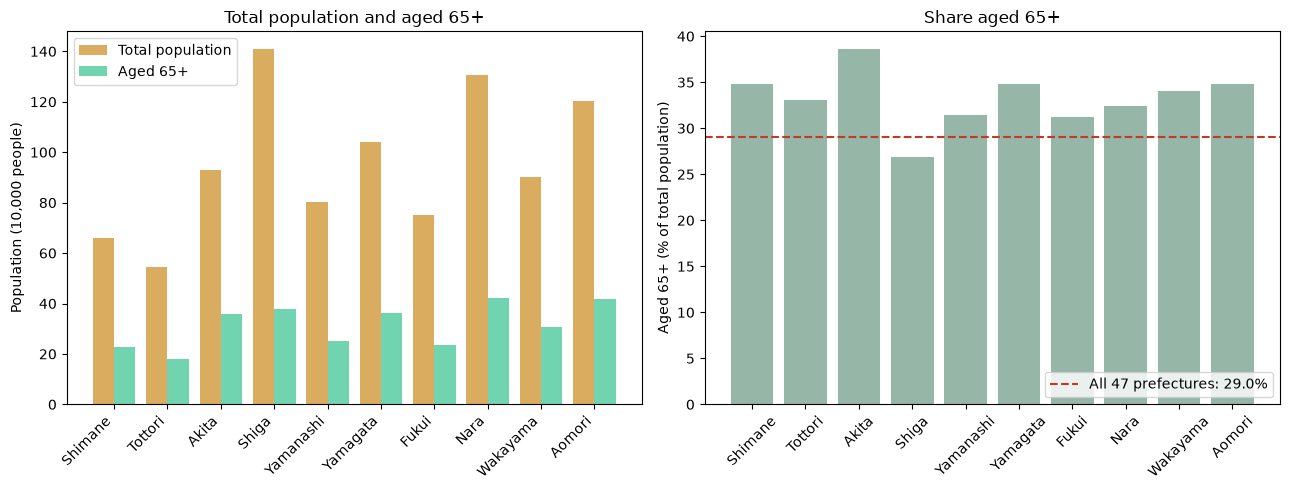

In [5]:
names = [r["en"] for r in rows]
total_man = [r["total"] / 10_000 for r in rows]
elderly_man = [r["elderly"] / 10_000 for r in rows]
shares = [r["share"] for r in rows]

# 47都道府県全体の65歳以上の割合
all_share = (sum(int(row["65歳以上人口"]) for row in data)
             / sum(int(row["総人口"]) for row in data) * 100)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

x = range(len(names))
width = 0.4
ax1.bar([i - width / 2 for i in x], total_man, width, label="Total population", color="#d9ac60")
ax1.bar([i + width / 2 for i in x], elderly_man, width, label="Aged 65+", color="#70d4b0")
ax1.set_xticks(list(x))
ax1.set_xticklabels(names, rotation=45, ha="right")
ax1.set_ylabel("Population (10,000 people)")
ax1.set_title("Total population and aged 65+")
ax1.legend()

ax2.bar(names, shares, color="#54886f9c")
ax2.axhline(all_share, color="#c0392b", linestyle="--", label=f"All 47 prefectures: {all_share:.1f}%")
ax2.set_ylabel("Aged 65+ (% of total population)")
ax2.set_title("Share aged 65+")
ax2.tick_params(axis="x", rotation=45)
ax2.legend(loc="lower right")

plt.tight_layout()
plt.show()

## 予想を確かめる（47都道府県の散布図）

予想は「病院が少ない県ほど、65歳以上人口も少ない」

TOP10だけでは判断できないので、47都道府県すべてを点で描き、TOP10を赤色にする。

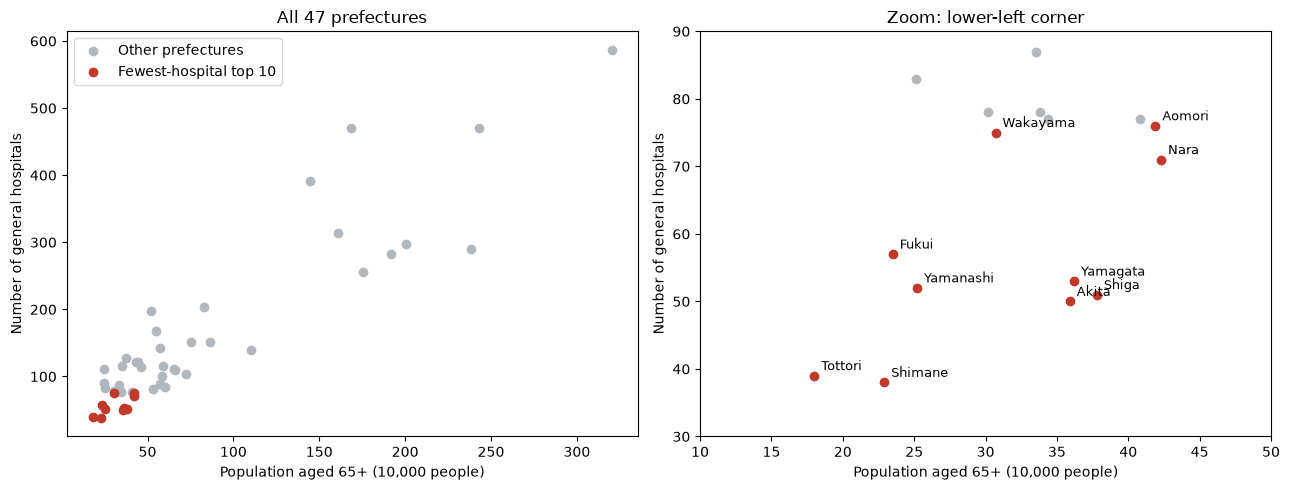

相関係数（47都道府県）: 0.92
相関係数（TOP10のみ）: 0.65


In [6]:
def correlation(xs, ys):
    n = len(xs)
    mean_x = sum(xs) / n
    mean_y = sum(ys) / n
    cov = sum((x - mean_x) * (y - mean_y) for x, y in zip(xs, ys))
    var_x = sum((x - mean_x) ** 2 for x in xs)
    var_y = sum((y - mean_y) ** 2 for y in ys)
    return cov / (var_x * var_y) ** 0.5

all_elderly = [int(row["65歳以上人口"]) / 10_000 for row in data]
all_hospitals = [int(row["一般病院数"]) for row in data]
top_names = [r["en"] for r in rows]

others = [row for row in data if row["Prefecture"] not in top_names]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

for ax in (ax1, ax2):
    ax.scatter([int(row["65歳以上人口"]) / 10_000 for row in others],
               [int(row["一般病院数"]) for row in others],
               color="#b0b7bd", label="Other prefectures")
    ax.scatter([r["elderly"] / 10_000 for r in rows],
               [r["hospitals"] for r in rows],
               color="#c0392b", label="Fewest-hospital top 10")
    ax.set_xlabel("Population aged 65+ (10,000 people)")
    ax.set_ylabel("Number of general hospitals")

ax1.set_title("All 47 prefectures")
ax1.legend(loc="upper left")

# 右：左下を拡大して、TOP10の県名を表示する
ax2.set_xlim(10, 50)
ax2.set_ylim(30, 90)
ax2.set_title("Zoom: lower-left corner")
for r in rows:
    ax2.annotate(r["en"], (r["elderly"] / 10_000, r["hospitals"]),
                 textcoords="offset points", xytext=(5, 4), fontsize=9)

plt.tight_layout()
plt.show()

print(f"相関係数（47都道府県）: {correlation(all_elderly, all_hospitals):.2f}")
print(f"相関係数（TOP10のみ）: {correlation([r['elderly'] for r in rows], [r['hospitals'] for r in rows]):.2f}")

##病院1つあたりの65歳以上人口

各地域の負担がどの程度か、「65歳以上人口 ÷ 一般病院数」を比べる。

点線は47都道府県全体の値で、これより右の県は、1つの病院が支える高齢者が全国より多い目安になる。

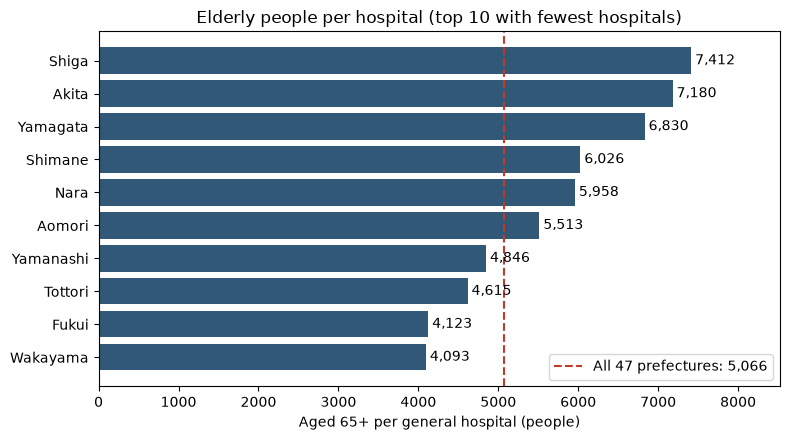

In [7]:
all_per_hospital = (sum(int(row["65歳以上人口"]) for row in data)
                    / sum(int(row["一般病院数"]) for row in data))

ordered = sorted(rows, key=lambda r: r["per_hospital"], reverse=True)
names = [r["en"] for r in ordered]
values = [r["per_hospital"] for r in ordered]

plt.figure(figsize=(8, 4.5))
bars = plt.barh(names, values, color="#315876")
plt.gca().invert_yaxis()
plt.axvline(all_per_hospital, color="#c0392b", linestyle="--",
            label=f"All 47 prefectures: {all_per_hospital:,.0f}")
for bar, value in zip(bars, values):
    plt.text(value + 50, bar.get_y() + bar.get_height() / 2, f"{value:,.0f}", va="center")
plt.xlabel("Aged 65+ per general hospital (people)")
plt.title("Elderly people per hospital (top 10 with fewest hospitals)")
plt.xlim(0, max(values) * 1.15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 元データとの確認（1位の県のみ）

In [8]:
first = rows[0]
original = [row for row in data if row["Prefecture"] == first["en"]][0]

print("表:", first["ja"], first["hospitals"], f"{first['elderly']:,}", f"{first['total']:,}")
print("CSV:", original["都道府県"], original["一般病院数"], original["65歳以上人口"], original["総人口"])
print("一致:", (first["hospitals"], first["elderly"], first["total"]) ==
              (int(original["一般病院数"]), int(original["65歳以上人口"]), int(original["総人口"])))

表: 島根県 38 229,000 658,000
CSV: 島根県 38 229000 658000
一致: True


-結果からわかったこと-

<結果>
- 一般病院数が少ない県が分かった。TOP10は山陰・東北・北陸・近畿などにある県が多いように感じた。

- 47都道府県で見ると、65歳以上人口と病院数の相関係数は約0.92と非常に強く、「病院が少ない県は高齢者数も少ない」という予想は、人数については当たっていた。（TOP10だけで見ると相関は約0.65に下がり、一定の傾向とは言いにくいとわかった。）
※割合だと、全国の65歳以上割合は約28.9%だが、TOP10は多くが全国より高い。一部は低いため、人数が少なくても、高齢化が進んでいないとは言えないとわかった。

- 病院1つあたりの65歳以上人口（TOP10の県のみ）を確認できた。

<確認>
島根県について、CSVの元の行と表の値が一致することを確かめ、一致していたため、データが取り出せたと確認できた。

<限界>
- 使ったCSV時点のデータのため、年ごとの推移、現在の状況は分からない。
- 取り出したのは一般病院数だけのため、診療所・介護施設・医師数や、病院の規模・診療科などは含んでいない。（病院数の少なさが、そのまま医療の不足を意味するとは言えないと思った。）
- 面積や交通アクセスなどは調べていないため、実際の利便性、状況などは分からない。

<提案>
- 高齢化の割合が高い県は、診療所・訪問診療・オンライン診療なども合わせて調べる。
- 最新の年や複数年のデータ、一般診療所数・医師数・面積を加え、本当の「推移」と医療の不足を比べられるようにする。

<week05からの改善点>
- 表示のみだったが、表とグラフを追加した。
- `japan.csv`を直接読み込む形に直した。
- 予想を47都道府県の散布図と相関係数で確かめた。